# 26a. Curvas de entrenamiento y diagnóstico de sobreajuste

Este cuaderno reproduce, a partir de los historiales guardados en cada corrida (`history.pkl`), las curvas de
entrenamiento y validación de NAGFuse y de los tres rivales más fuertes. Para cada época se muestra la media entre
semillas y una banda de ± 1 desviación estándar. La línea vertical punteada marca la mediana de la época elegida
por *early stopping* (máximo F1 macro en validación). Los entrenamientos son costosos (≈ 19 h de GPU), así que se
usan resultados precalculados y versionados; el código que los genera es `entregable3/e3/worker.py`.

In [1]:
# Configuración común. El cuaderno funciona desde docs/ (Jupyter Book) o desde la raíz del repositorio.
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable3").is_dir())
RES = REPO / "entregable3" / "resultados"   # tablas congeladas del análisis (hash SHA-256 en el capítulo 21)
RUNS = REPO / "entregable3" / "results"     # corridas versionadas, sin pesos
CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
COLOR = {"NAGFuse": "#c0392b", "ViT-B16": "#2e86c1", "RWCNet": "#27ae60", "GFN": "#8e44ad", "Celik-HC": "#d68910"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 4)
print("Repositorio:", REPO.name)

Repositorio: deep-learning-colaborativo


In [2]:
# Carga los historiales por época de cada modelo y semilla (solo corridas terminadas, con archivo DONE)
def historiales(modelo: str) -> pd.DataFrame:
    filas = []
    for s in sorted((RUNS / "results_e2" / modelo).glob("seed_*")):
        if not (s / "DONE").exists():
            continue
        h = pickle.load(open(s / "history.pkl", "rb"))                 # dict de listas, una entrada por época
        t = pickle.load(open(s / "timing.pkl", "rb"))                  # incluye best_epoch y tiempos
        filas.append(pd.DataFrame({"modelo": modelo, "semilla": int(s.name[5:]), "epoca": h["epoch"],
                                   "train_loss": h["train_loss"], "val_loss": h["val_loss"],
                                   "train_f1": h["train_f1_macro"], "val_f1": h["val_f1_macro"],
                                   "mejor_epoca": t["best_epoch"]}))
    return pd.concat(filas)

MODELOS = ["NAGFuse", "ViT-B16", "RWCNet", "GFN"]
H = pd.concat([historiales(m) for m in MODELOS])
H.groupby("modelo").semilla.nunique().rename("semillas")

modelo
GFN        12
NAGFuse    20
RWCNet     12
ViT-B16    12
Name: semillas, dtype: int64

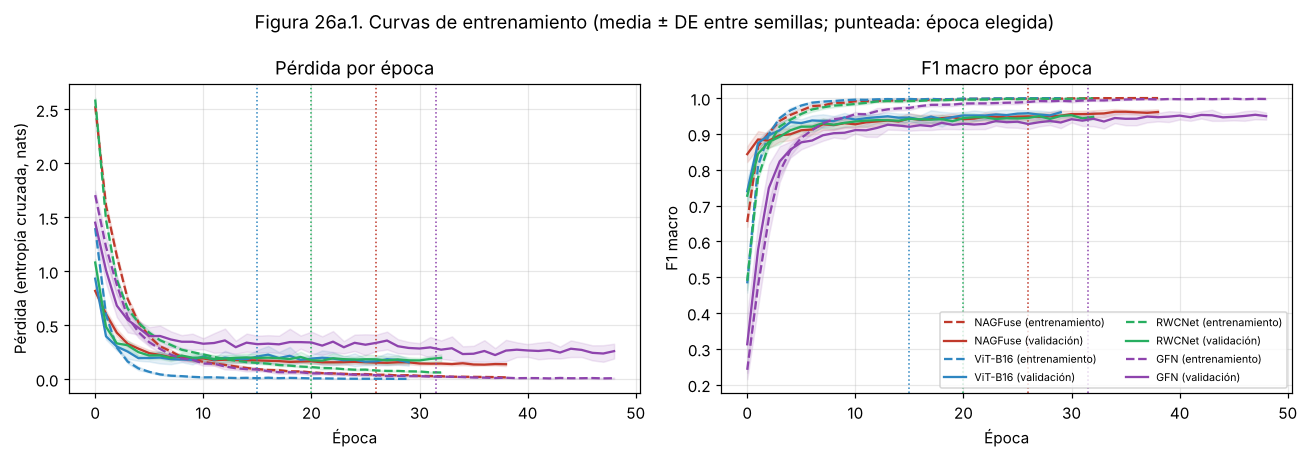

In [3]:
# Figura 26a.1: pérdida y F1 macro por época (media ± DE entre semillas)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, met, nombre in [(ejes[0], "loss", "Pérdida (entropía cruzada, nats)"), (ejes[1], "f1", "F1 macro")]:
    for m in MODELOS:
        g = H[H.modelo == m].groupby("epoca")
        for parte, estilo in [("train", "--"), ("val", "-")]:
            col = f"{parte}_{met}"
            n = g[col].count(); ok = n >= max(2, n.max() / 2)    # épocas a las que llegó al menos la mitad de las semillas
            mu, sd = g[col].mean()[ok], g[col].std().fillna(0)[ok]
            ax.plot(mu.index, mu, estilo, color=COLOR[m], label=f"{m} ({'entrenamiento' if parte == 'train' else 'validación'})")
            ax.fill_between(mu.index, mu - sd, mu + sd, color=COLOR[m], alpha=0.12)
        ax.axvline(H[H.modelo == m].groupby("semilla").mejor_epoca.first().median(), color=COLOR[m], ls=":", lw=1)
    ax.set_xlabel("Época"); ax.set_ylabel(nombre)
ejes[0].set_title("Pérdida por época"); ejes[1].set_title("F1 macro por época")
ejes[1].legend(fontsize=7, ncol=2, loc="lower right")
fig.suptitle("Figura 26a.1. Curvas de entrenamiento (media ± DE entre semillas; punteada: época elegida)")
plt.tight_layout()

**Interpretación.** Las cuatro redes, todas preentrenadas en ImageNet, bajan la pérdida de entrenamiento casi a
cero mientras la de validación se estanca o sube después de las primeras épocas: es el patrón típico de un *fine-tuning*
sobre un conjunto pequeño (1800 imágenes). El *early stopping* corta en la zona donde el F1 de validación ya es
estable, así que el sobreajuste de la pérdida no se traslada al F1. La tabla siguiente lo cuantifica.

In [4]:
# Tabla 26a.1: diagnóstico de sobreajuste en la época elegida, por semilla y luego media ± DE entre semillas
def en_mejor(d):
    r = d[d.epoca == d.mejor_epoca.iloc[0]].iloc[0]
    return pd.Series({"mejor_epoca": r.epoca, "epocas_corridas": d.epoca.max() + 1, "F1_train": r.train_f1,
                      "F1_val": r.val_f1, "brecha_F1": r.train_f1 - r.val_f1, "perdida_val": r.val_loss})

D = H.groupby(["modelo", "semilla"]).apply(en_mejor, include_groups=False)
tabla = D.groupby("modelo").agg(["mean", "std"]).round(4)
tabla.columns = [f"{a} ({'media' if b == 'mean' else 'DE'})" for a, b in tabla.columns]
tabla

,mejor_epoca (media),mejor_epoca (DE),epocas_corridas (media),epocas_corridas (DE),F1_train (media),F1_train (DE),F1_val (media),F1_val (DE),brecha_F1 (media),brecha_F1 (DE),perdida_val (media),perdida_val (DE)
modelo,,,,,,,,,,,,
GFN,29.9167,12.0865,42.9167,12.0865,0.9893,0.0105,0.9555,0.0111,0.0338,0.0123,0.2150,0.0528
NAGFuse,26.9000,10.8865,39.7000,10.4484,0.9979,0.0024,0.9665,0.0063,0.0314,0.0054,0.1335,0.0145
RWCNet,19.1667,9.3501,32.1667,9.3501,0.9924,0.0083,0.9587,0.0077,0.0337,0.0070,0.1626,0.0292
ViT-B16,15.4167,6.5430,28.4167,6.5430,0.9949,0.0075,0.9648,0.0065,0.0301,0.0054,0.1517,0.0351


**Lectura de la tabla.** En los cuatro modelos el F1 de validación en la época elegida es de 0.955–0.967 y la
brecha con el de entrenamiento es de unos 3 puntos, sin diferencias grandes entre ellos. La brecha entre el F1 de entrenamiento y el de validación en la época elegida mide el
sobreajuste que queda después del *early stopping*. Una brecha de pocos puntos con F1 de validación estable entre
semillas indica que el modelo generaliza dentro de la distribución de TrashNet. La generalización fuera de ella es
otro problema (conjuntos adicionales, capítulo 28).

**Curva de aprendizaje frente al tamaño de muestra.** El enunciado (Sección 8.8) pide reentrenar con el 10 %, 25 % y
50 % del entrenamiento. No se hizo, por falta de presupuesto de cómputo (cada punto exige reentrenar los modelos con
varias semillas). Queda declarado como limitación en los capítulos 29 y 30.